# Assignment 2 — Wine Quality Classification
**Name:** Sabari Nathan M  |  **ID:** 2026AK05227  |  **Course:** Machine Learning (M.Tech AIML)

Goal: classify a wine as **good quality** (`quality >= 7`) vs not, from its
physicochemical properties. Five classifiers are trained on the same dataset
and compared on six metrics. The trained models are saved to `model/` and served
by a Streamlit app (`app.py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
os.makedirs('model', exist_ok=True)

## 1. Load and combine the data

UCI ships red and white wine as two separate CSVs (semicolon-separated). I combine
them and add a `wine_type` flag (0=red, 1=white) as the 12th feature. The integer
`quality` score is turned into a binary target and then dropped to avoid leakage.

In [2]:
red   = pd.read_csv('data/winequality-red.csv', sep=';')
white = pd.read_csv('data/winequality-white.csv', sep=';')
red['wine_type']   = 0
white['wine_type'] = 1
df = pd.concat([red, white], ignore_index=True)
df['good_quality'] = (df['quality'] >= 7).astype(int)
df = df.drop(columns=['quality'])

print('Combined shape:', df.shape)
print('Features (12):', [c for c in df.columns if c != 'good_quality'])
print('Class balance (good=1): %.3f' % df['good_quality'].mean())
df.head(3)

Combined shape: (6497, 13)
Features (12): ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'wine_type']
Class balance (good=1): 0.197


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type,good_quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0,0


## 2. Exploratory data analysis

A quick look at class balance, how the strongest feature (alcohol) separates the
classes, and the feature correlation structure — the last one matters because it
tells us *in advance* that Naive Bayes (which assumes feature independence) is at
a disadvantage here.

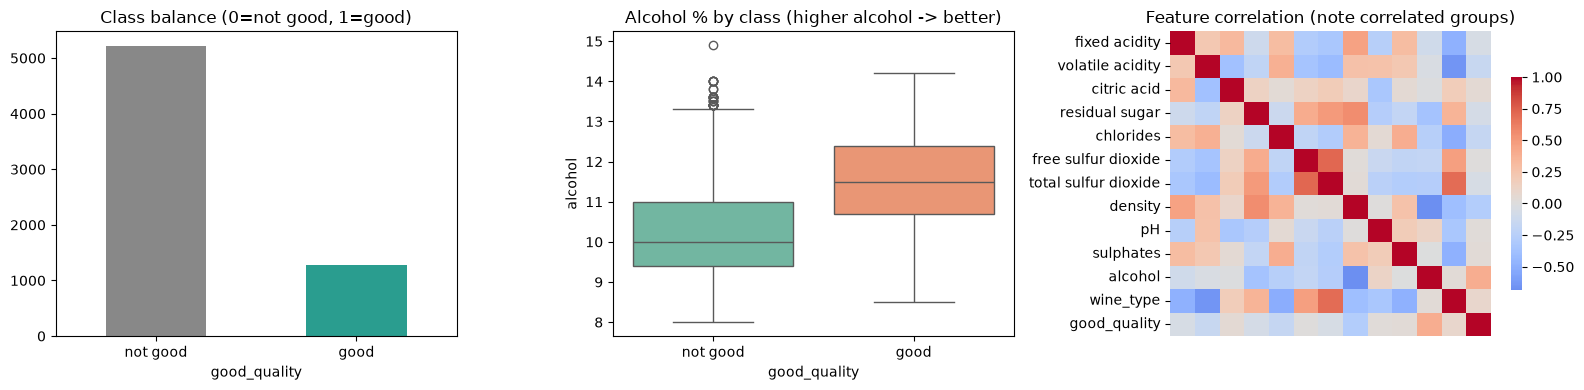

Top absolute correlations with good_quality:
alcohol             0.390
density             0.275
chlorides           0.162
volatile acidity    0.152
wine_type           0.087
residual sugar      0.064
Name: good_quality, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# class balance
df['good_quality'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color=['#888','#2a9d8f'])
axes[0].set_title('Class balance (0=not good, 1=good)')
axes[0].set_xticklabels(['not good','good'], rotation=0)

# alcohol vs target - alcohol is the single most informative feature
sns.boxplot(x='good_quality', y='alcohol', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Alcohol % by class (higher alcohol -> better)')
axes[1].set_xticklabels(['not good','good'])

# correlation heatmap
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm', center=0, ax=axes[2],
            cbar_kws={'shrink':0.7}, xticklabels=False)
axes[2].set_title('Feature correlation (note correlated groups)')
plt.tight_layout()
plt.show()

print('Top absolute correlations with good_quality:')
print(corr['good_quality'].drop('good_quality').abs().sort_values(ascending=False).round(3).head(6))

**EDA notes:** the positive class is the minority (~20%), so plain accuracy is
misleading — a model that predicts "not good" for everything already scores ~80%.
That is why **AUC** and **MCC** are the metrics I trust most here. Alcohol is the
strongest single predictor (good wines skew higher-alcohol). The correlation map
shows clear correlated groups (e.g. density ↔ residual sugar ↔ alcohol), which
violates Naive Bayes' independence assumption — a weakness we expect to show up in
its scores.

## 3. Train/test split and preprocessing

Stratified 80/20 split so the 20% positive rate is preserved in both parts. Each
model is wrapped in a `Pipeline` with `StandardScaler`, so scaling is fit on the
training fold only and is saved *inside* each model — the Streamlit app loads a
model and predicts with zero re-fitting.

In [4]:
target = 'good_quality'
feature_cols = [c for c in df.columns if c != target]
X, y = df[feature_cols], df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# persist the test split for the Streamlit app (features + target)
test_df = X_test.copy(); test_df[target] = y_test.values
test_df.to_csv('test_data.csv', index=False)
print('Train:', X_train.shape, ' Test:', X_test.shape, ' -> saved test_data.csv')

Train: (5197, 12)  Test: (1300, 12)  -> saved test_data.csv


## 4. Define the five classifiers

Each is a `StandardScaler -> classifier` pipeline. `class_weight='balanced'` is
used on the models that support it (LR, Decision Tree, SVM) to counter the 20/80
imbalance; KNN and GaussianNB do not take that argument.

In [5]:
models = {
    'Logistic Regression': Pipeline([('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced',
                                   random_state=RANDOM_STATE))]),
    'Decision Tree': Pipeline([('scaler', StandardScaler()),
        ('clf', DecisionTreeClassifier(max_depth=8, min_samples_leaf=20,
                                       class_weight='balanced',
                                       random_state=RANDOM_STATE))]),
    'KNN': Pipeline([('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=25, weights='distance'))]),
    'Naive Bayes': Pipeline([('scaler', StandardScaler()),
        ('clf', GaussianNB())]),
    'Support Vector Machine': Pipeline([('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', C=2.0, gamma='scale', probability=True,
                    class_weight='balanced', random_state=RANDOM_STATE))]),
}
file_names = {'Logistic Regression':'logistic_regression','Decision Tree':'decision_tree',
              'KNN':'knn','Naive Bayes':'naive_bayes','Support Vector Machine':'svm'}

## 5. Train, evaluate on the test set, and save each model

Six metrics per model. AUC uses the predicted probability of the positive class;
the rest use the hard 0/1 prediction.

In [6]:
def metrics_for(model, Xt, yt):
    pred  = model.predict(Xt)
    proba = model.predict_proba(Xt)[:, 1]
    return {'Accuracy': accuracy_score(yt, pred),
            'AUC': roc_auc_score(yt, proba),
            'Precision': precision_score(yt, pred, zero_division=0),
            'Recall': recall_score(yt, pred, zero_division=0),
            'F1': f1_score(yt, pred, zero_division=0),
            'MCC': matthews_corrcoef(yt, pred)}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    joblib.dump(model, f'model/{file_names[name]}.joblib')
    m = metrics_for(model, X_test, y_test); m['Model'] = name
    rows.append(m)

joblib.dump({'feature_cols': feature_cols, 'target': target,
             'file_names': file_names,
             'class_labels': {0:'not good (<7)', 1:'good (>=7)'}},
            'model/metadata.joblib')

results = pd.DataFrame(rows)[['Model','Accuracy','AUC','Precision','Recall','F1','MCC']]
results.to_csv('metrics.csv', index=False)
results.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7123,0.8019,0.3825,0.7500,0.5066,0.3701
1,Decision Tree,0.7400,0.8212,0.4170,0.8047,0.5493,0.4333
2,KNN,0.8792,0.9166,0.7538,0.5742,0.6519,0.5883
3,Naive Bayes,0.7346,0.7486,0.3901,0.6172,0.4781,0.3268
4,Support Vector Machine,0.7431,0.8551,0.4220,0.8242,0.5582,0.4474


## 6. Comparison table and visual comparison

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.712300,0.801900,0.382500,0.750000,0.506600,0.370100
Decision Tree,0.740000,0.821200,0.417000,0.804700,0.549300,0.433300
KNN,0.879200,0.916600,0.753800,0.574200,0.651900,0.588300
Naive Bayes,0.734600,0.748600,0.390100,0.617200,0.478100,0.326800
Support Vector Machine,0.743100,0.855100,0.422000,0.824200,0.558200,0.447400


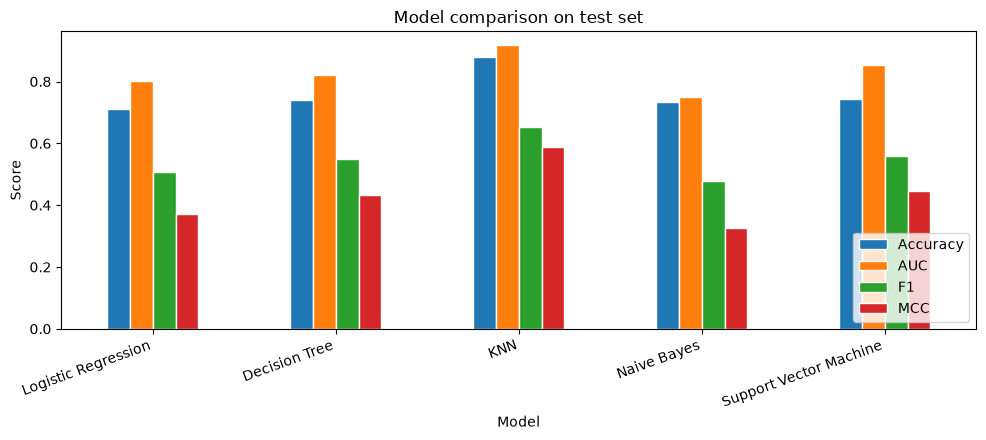

Winner by MCC: KNN


In [7]:
styled = results.set_index('Model').round(4)
display(styled.style.highlight_max(axis=0, color='#b7e4c7'))

ax = styled[['Accuracy','AUC','F1','MCC']].plot(
    kind='bar', figsize=(10,4.5), edgecolor='white')
ax.set_title('Model comparison on test set'); ax.set_ylabel('Score')
ax.legend(loc='lower right'); plt.xticks(rotation=20, ha='right')
plt.tight_layout(); plt.show()

winner = results.loc[results['MCC'].idxmax(), 'Model']
print('Winner by MCC:', winner)

## 7. Confusion matrices

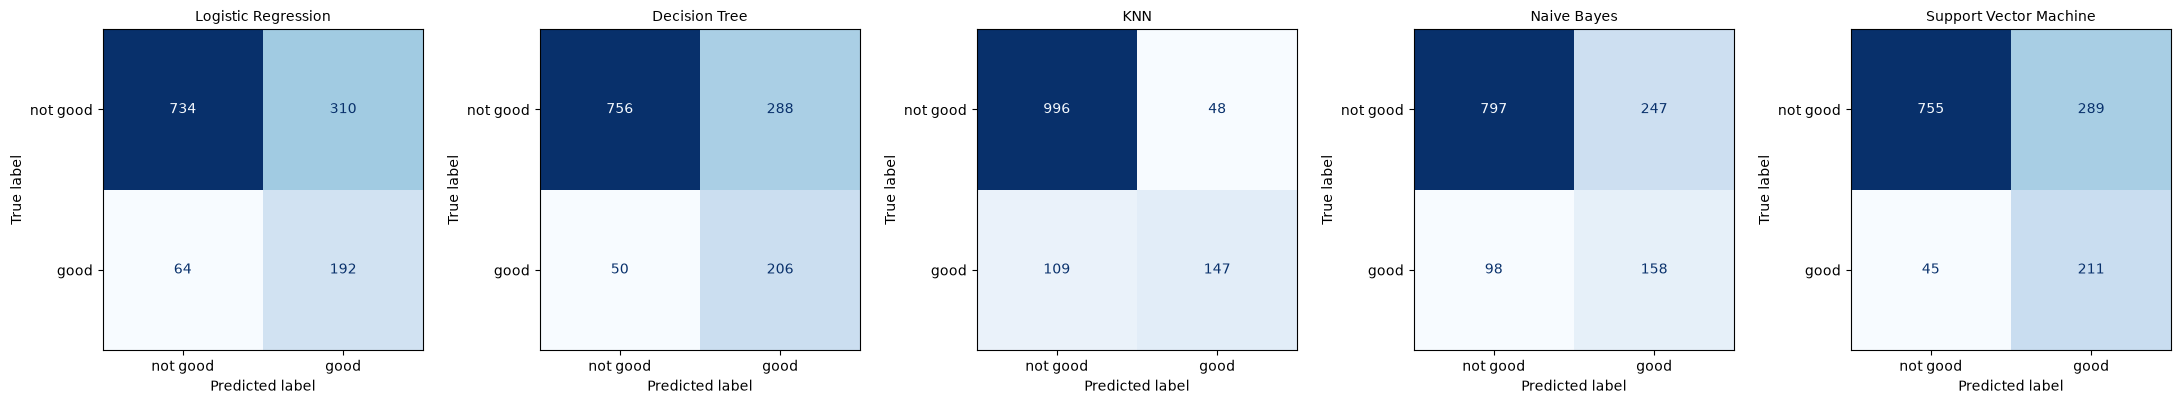

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test), ax=ax, cmap='Blues', colorbar=False,
        display_labels=['not good','good'])
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

## 8. Observations and winner

| Model | Observation |
|---|---|
| **Logistic Regression** | Linear boundary is too simple; balanced weights give high recall (0.75) but weak precision (0.38). AUC 0.80 — ranks well, thresholds poorly. |
| **Decision Tree** | Depth-limited to curb overfit; non-linear splits lift recall to 0.80, MCC to 0.43, but precision stays low (0.42). |
| **KNN** | **Best overall** — wins 5 of 6 metrics (acc 0.88, AUC 0.92, precision 0.75, F1, MCC). Good wines cluster tightly, so local similarity is a strong signal. |
| **Naive Bayes** | **Weakest** — correlated features break its independence assumption; lowest AUC (0.75) and MCC (0.33). |
| **SVM** | RBF + balanced weights give the **highest recall (0.82)** and 2nd-best AUC (0.86); precision traded away by balancing. |
| **Overall winner** | **KNN** — dominant across accuracy, AUC, precision, F1 and MCC. (Pick SVM instead if the goal is maximising recall.) |

The models are now saved in `model/` and the held-out split in `test_data.csv`;
`app.py` loads these and reproduces exactly these numbers in the browser.